NAIVE BAYES CLASSIFIER - COMPREHENSIVE ANALYSIS

[1] Creating Datasets...
Categorical Dataset Shape: (1000, 5)
Mixed Dataset Shape: (1000, 6)

[2] Categorical Dataset Sample:
  Weather Temperature Humidity      Wind PlayTennis
0  Cloudy        Warm      Low  Moderate        Yes
1   Snowy        Cool   Medium    Strong        Yes
2   Sunny         Hot      Low  Moderate        Yes
3  Cloudy         Hot      Low      Weak        Yes
4  Cloudy         Hot     High    Strong         No

[3] Mixed Dataset Sample:
   Age        Income  CreditScore    Education     Employment LoanStatus
0   56  17871.073595          400          PhD     Unemployed   Rejected
1   69  54069.272717          431          PhD  Self-Employed   Approved
2   46  34872.985094          680       Master       Employed   Approved
3   32  21554.925808          431  High School     Unemployed   Rejected
4   60  37068.542315          319  High School       Employed   Rejected

EXPERIMENT 1: CATEGORICAL DATASET

[1] Training

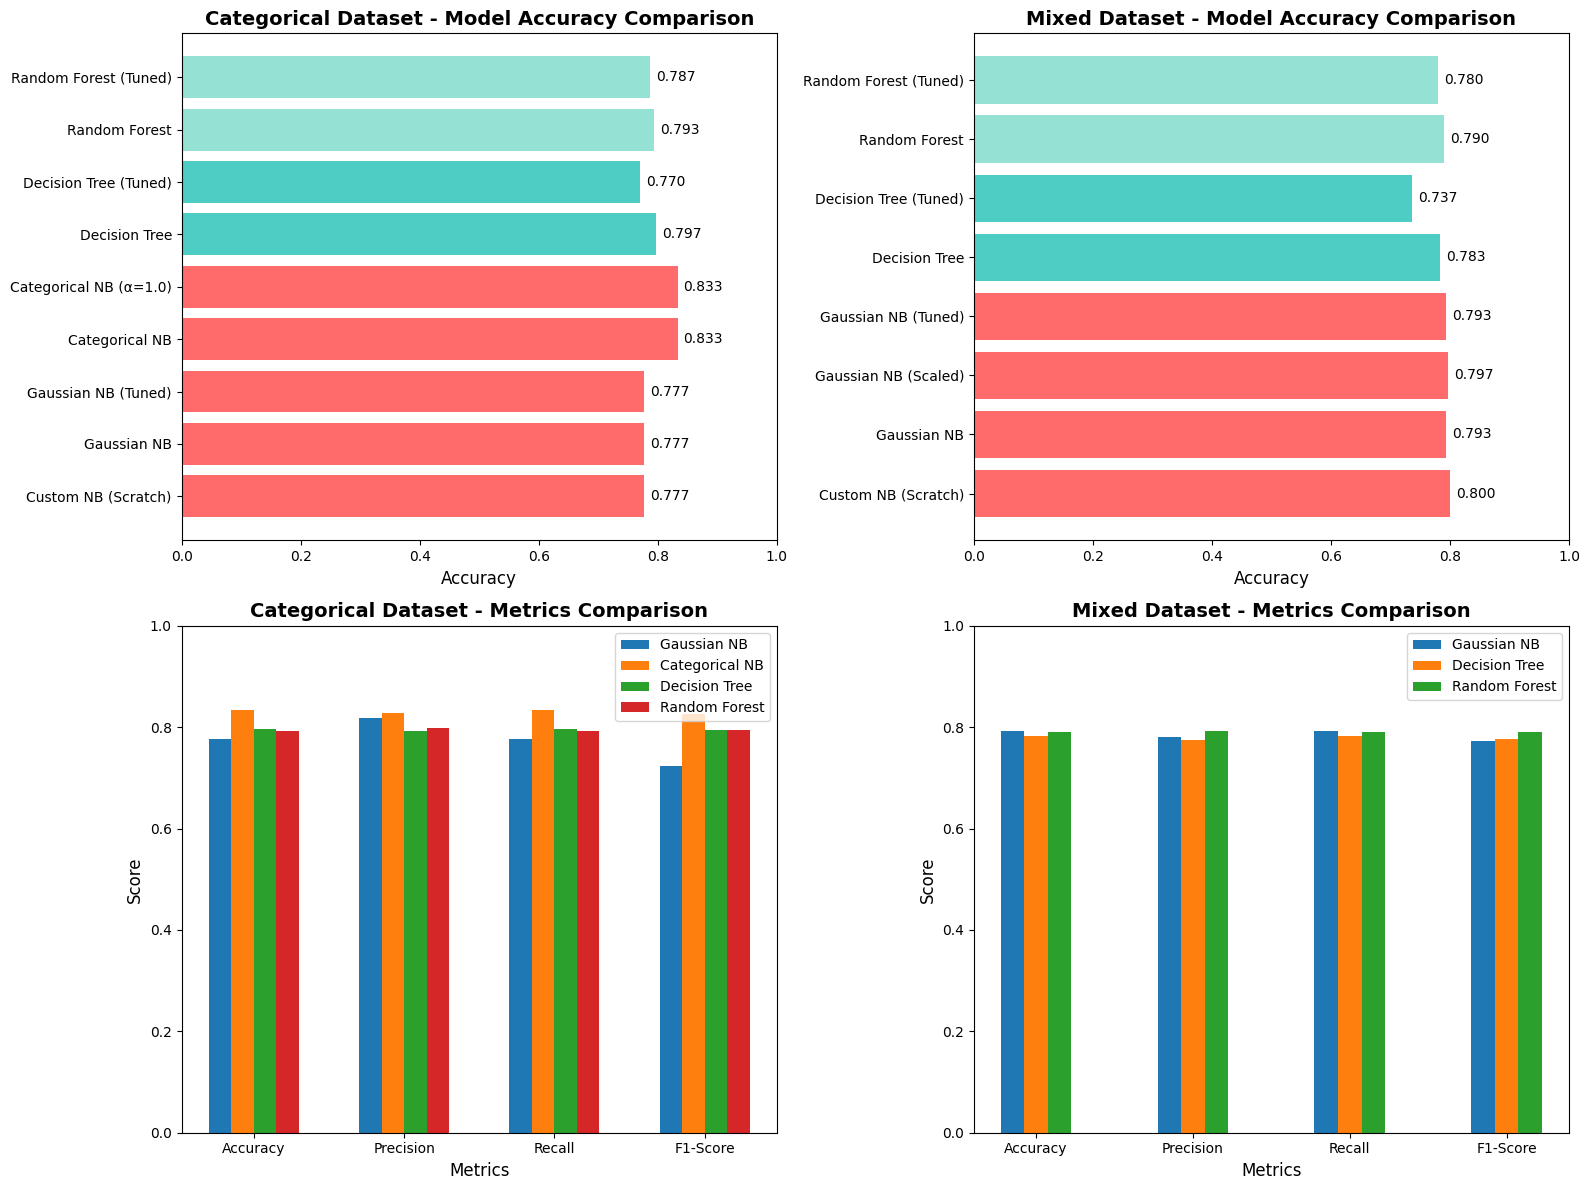


FINAL SUMMARY

Best Model for Categorical Dataset:
  Categorical NB: Accuracy = 0.8333

Best Model for Mixed Dataset:
  Custom NB (Scratch): Accuracy = 0.8000

ANALYSIS COMPLETE!


In [1]:
# Naive Bayes Classifier - Complete Implementation
# Run this in Google Colab - all cells are ready to execute

# ============================================================================
# SECTION 1: IMPORTS AND SETUP
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB, MultinomialNB, CategoricalNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
from sklearn.datasets import make_classification
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# ============================================================================
# SECTION 2: NAIVE BAYES FROM SCRATCH
# ============================================================================

class NaiveBayesClassifier:
    """Naive Bayes Classifier implemented from scratch"""

    def __init__(self):
        self.classes = None
        self.class_priors = {}
        self.feature_probs = {}
        self.numerical_stats = {}

    def fit(self, X, y):
        """Train the Naive Bayes classifier"""
        self.classes = np.unique(y)
        n_samples = len(y)

        # Calculate class priors
        for c in self.classes:
            self.class_priors[c] = np.sum(y == c) / n_samples

        # Calculate feature probabilities
        for c in self.classes:
            X_c = X[y == c]
            self.feature_probs[c] = {}
            self.numerical_stats[c] = {}

            for feature_idx in range(X.shape[1]):
                feature_values = X_c[:, feature_idx]

                # Check if feature is numerical
                if np.issubdtype(feature_values.dtype, np.number):
                    # For numerical features, store mean and std
                    self.numerical_stats[c][feature_idx] = {
                        'mean': np.mean(feature_values),
                        'std': np.std(feature_values) + 1e-6  # Add small value to avoid division by zero
                    }
                else:
                    # For categorical features, calculate probabilities
                    unique_vals, counts = np.unique(feature_values, return_counts=True)
                    total = len(feature_values)
                    self.feature_probs[c][feature_idx] = dict(zip(unique_vals, counts / total))

    def _gaussian_probability(self, x, mean, std):
        """Calculate Gaussian probability"""
        exponent = np.exp(-((x - mean) ** 2) / (2 * std ** 2))
        return (1 / (np.sqrt(2 * np.pi) * std)) * exponent

    def predict(self, X):
        """Predict class labels for samples in X"""
        predictions = []

        for sample in X:
            class_scores = {}

            for c in self.classes:
                # Start with class prior
                score = np.log(self.class_priors[c])

                # Multiply by feature probabilities
                for feature_idx, feature_val in enumerate(sample):
                    if feature_idx in self.numerical_stats[c]:
                        # Numerical feature
                        stats = self.numerical_stats[c][feature_idx]
                        prob = self._gaussian_probability(feature_val, stats['mean'], stats['std'])
                        score += np.log(prob + 1e-6)
                    else:
                        # Categorical feature
                        if feature_val in self.feature_probs[c][feature_idx]:
                            score += np.log(self.feature_probs[c][feature_idx][feature_val] + 1e-6)
                        else:
                            score += np.log(1e-6)  # Laplace smoothing

                class_scores[c] = score

            predictions.append(max(class_scores, key=class_scores.get))

        return np.array(predictions)

# ============================================================================
# SECTION 3: CREATE DATASETS
# ============================================================================

def create_categorical_dataset():
    """Create a dataset with all categorical attributes"""
    np.random.seed(42)
    n_samples = 1000

    # Generate categorical features
    weather = np.random.choice(['Sunny', 'Rainy', 'Cloudy', 'Snowy'], n_samples)
    temperature = np.random.choice(['Hot', 'Warm', 'Cool', 'Cold'], n_samples)
    humidity = np.random.choice(['High', 'Medium', 'Low'], n_samples)
    wind = np.random.choice(['Strong', 'Moderate', 'Weak'], n_samples)

    # Create target based on conditions (play tennis scenario)
    target = []
    for i in range(n_samples):
        score = 0
        if weather[i] in ['Sunny', 'Cloudy']:
            score += 1
        if temperature[i] in ['Warm', 'Cool']:
            score += 1
        if humidity[i] in ['Low', 'Medium']:
            score += 1
        if wind[i] in ['Weak', 'Moderate']:
            score += 1

        # Add some randomness
        score += np.random.randint(-1, 2)
        target.append('Yes' if score >= 2 else 'No')

    df = pd.DataFrame({
        'Weather': weather,
        'Temperature': temperature,
        'Humidity': humidity,
        'Wind': wind,
        'PlayTennis': target
    })

    return df

def create_mixed_dataset():
    """Create a dataset with mixed (categorical + numerical) attributes"""
    np.random.seed(42)
    n_samples = 1000

    # Numerical features
    age = np.random.randint(18, 70, n_samples)
    income = np.random.normal(50000, 20000, n_samples)
    credit_score = np.random.randint(300, 850, n_samples)

    # Categorical features
    education = np.random.choice(['High School', 'Bachelor', 'Master', 'PhD'], n_samples)
    employment = np.random.choice(['Employed', 'Unemployed', 'Self-Employed'], n_samples)

    # Create target based on conditions (loan approval)
    target = []
    for i in range(n_samples):
        score = 0
        if age[i] > 25 and age[i] < 60:
            score += 1
        if income[i] > 40000:
            score += 1
        if credit_score[i] > 650:
            score += 1
        if education[i] in ['Bachelor', 'Master', 'PhD']:
            score += 1
        if employment[i] in ['Employed', 'Self-Employed']:
            score += 1

        # Add randomness
        score += np.random.randint(-1, 2)
        target.append('Approved' if score >= 3 else 'Rejected')

    df = pd.DataFrame({
        'Age': age,
        'Income': income,
        'CreditScore': credit_score,
        'Education': education,
        'Employment': employment,
        'LoanStatus': target
    })

    return df

# ============================================================================
# SECTION 4: DATA PREPROCESSING
# ============================================================================

def preprocess_categorical_data(df, target_col):
    """Preprocess categorical dataset"""
    X = df.drop(target_col, axis=1)
    y = df[target_col]

    # Encode categorical variables
    le_dict = {}
    X_encoded = X.copy()
    for col in X.columns:
        le = LabelEncoder()
        X_encoded[col] = le.fit_transform(X[col])
        le_dict[col] = le

    # Encode target
    le_target = LabelEncoder()
    y_encoded = le_target.fit_transform(y)

    return X_encoded.values, y_encoded, X, y

def preprocess_mixed_data(df, target_col, scale=False):
    """Preprocess mixed dataset"""
    X = df.drop(target_col, axis=1)
    y = df[target_col]

    # Separate numerical and categorical columns
    num_cols = X.select_dtypes(include=[np.number]).columns
    cat_cols = X.select_dtypes(exclude=[np.number]).columns

    X_processed = X.copy()

    # Encode categorical variables
    for col in cat_cols:
        le = LabelEncoder()
        X_processed[col] = le.fit_transform(X[col])

    # Scale numerical features if requested
    if scale:
        scaler = StandardScaler()
        X_processed[num_cols] = scaler.fit_transform(X_processed[num_cols])

    # Encode target
    le_target = LabelEncoder()
    y_encoded = le_target.fit_transform(y)

    return X_processed.values, y_encoded, X, y

# ============================================================================
# SECTION 5: EVALUATION FUNCTIONS
# ============================================================================

def evaluate_model(model, X_train, X_test, y_train, y_test, model_name):
    """Evaluate a model and return metrics"""
    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    y_pred = model.predict(X_test)

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, y_pred, average='weighted', zero_division=0)

    # Cross-validation score
    cv_scores = cross_val_score(model, X_train, y_train, cv=5)
    cv_mean = cv_scores.mean()
    cv_std = cv_scores.std()

    return {
        'Model': model_name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'CV Mean': cv_mean,
        'CV Std': cv_std
    }

# ============================================================================
# SECTION 6: RUN EXPERIMENTS
# ============================================================================

print("="*80)
print("NAIVE BAYES CLASSIFIER - COMPREHENSIVE ANALYSIS")
print("="*80)

# Create datasets
print("\n[1] Creating Datasets...")
df_categorical = create_categorical_dataset()
df_mixed = create_mixed_dataset()

print(f"Categorical Dataset Shape: {df_categorical.shape}")
print(f"Mixed Dataset Shape: {df_mixed.shape}")

# Display sample data
print("\n[2] Categorical Dataset Sample:")
print(df_categorical.head())

print("\n[3] Mixed Dataset Sample:")
print(df_mixed.head())

# ============================================================================
# EXPERIMENT 1: CATEGORICAL DATASET
# ============================================================================

print("\n" + "="*80)
print("EXPERIMENT 1: CATEGORICAL DATASET")
print("="*80)

X_cat, y_cat, X_cat_orig, y_cat_orig = preprocess_categorical_data(df_categorical, 'PlayTennis')
X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_cat, y_cat, test_size=0.3, random_state=42
)

results_categorical = []

# 1. Custom Naive Bayes (from scratch)
print("\n[1] Training Custom Naive Bayes (from scratch)...")
custom_nb = NaiveBayesClassifier()
custom_nb.fit(X_train_cat, y_train_cat)
y_pred_custom = custom_nb.predict(X_test_cat)
results_categorical.append({
    'Model': 'Custom NB (Scratch)',
    'Accuracy': accuracy_score(y_test_cat, y_pred_custom),
    'Precision': precision_score(y_test_cat, y_pred_custom, average='weighted'),
    'Recall': recall_score(y_test_cat, y_pred_custom, average='weighted'),
    'F1-Score': f1_score(y_test_cat, y_pred_custom, average='weighted'),
    'CV Mean': '-',
    'CV Std': '-'
})

# 2. Gaussian Naive Bayes
print("[2] Training Gaussian Naive Bayes...")
gnb = GaussianNB()
results_categorical.append(evaluate_model(gnb, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Gaussian NB'))

# 3. Gaussian NB with var_smoothing tuning
print("[3] Training Gaussian NB with hyperparameter tuning...")
gnb_tuned = GaussianNB(var_smoothing=1e-8)
results_categorical.append(evaluate_model(gnb_tuned, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Gaussian NB (Tuned)'))

# 4. Categorical Naive Bayes
print("[4] Training Categorical Naive Bayes...")
cnb = CategoricalNB()
results_categorical.append(evaluate_model(cnb, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Categorical NB'))

# 5. Categorical NB with different alpha
print("[5] Training Categorical NB with Laplace smoothing...")
cnb_smooth = CategoricalNB(alpha=1.0)
results_categorical.append(evaluate_model(cnb_smooth, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Categorical NB (α=1.0)'))

# 6. Decision Tree
print("[6] Training Decision Tree...")
dt = DecisionTreeClassifier(random_state=42, max_depth=5)
results_categorical.append(evaluate_model(dt, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Decision Tree'))

# 7. Decision Tree with tuning
print("[7] Training Decision Tree with hyperparameter tuning...")
dt_tuned = DecisionTreeClassifier(random_state=42, max_depth=10, min_samples_split=5, min_samples_leaf=2)
results_categorical.append(evaluate_model(dt_tuned, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Decision Tree (Tuned)'))

# 8. Random Forest
print("[8] Training Random Forest...")
rf = RandomForestClassifier(random_state=42, n_estimators=100)
results_categorical.append(evaluate_model(rf, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Random Forest'))

# 9. Random Forest with tuning
print("[9] Training Random Forest with hyperparameter tuning...")
rf_tuned = RandomForestClassifier(random_state=42, n_estimators=200, max_depth=10, min_samples_split=5)
results_categorical.append(evaluate_model(rf_tuned, X_train_cat, X_test_cat, y_train_cat, y_test_cat, 'Random Forest (Tuned)'))

# Create results DataFrame
df_results_cat = pd.DataFrame(results_categorical)
print("\n" + "="*80)
print("RESULTS - CATEGORICAL DATASET")
print("="*80)
print(df_results_cat.to_string(index=False))

# ============================================================================
# EXPERIMENT 2: MIXED DATASET
# ============================================================================

print("\n" + "="*80)
print("EXPERIMENT 2: MIXED DATASET")
print("="*80)

X_mix, y_mix, X_mix_orig, y_mix_orig = preprocess_mixed_data(df_mixed, 'LoanStatus', scale=False)
X_train_mix, X_test_mix, y_train_mix, y_test_mix = train_test_split(
    X_mix, y_mix, test_size=0.3, random_state=42
)

results_mixed = []

# 1. Custom Naive Bayes (from scratch)
print("\n[1] Training Custom Naive Bayes (from scratch)...")
custom_nb_mix = NaiveBayesClassifier()
custom_nb_mix.fit(X_train_mix, y_train_mix)
y_pred_custom_mix = custom_nb_mix.predict(X_test_mix)
results_mixed.append({
    'Model': 'Custom NB (Scratch)',
    'Accuracy': accuracy_score(y_test_mix, y_pred_custom_mix),
    'Precision': precision_score(y_test_mix, y_pred_custom_mix, average='weighted'),
    'Recall': recall_score(y_test_mix, y_pred_custom_mix, average='weighted'),
    'F1-Score': f1_score(y_test_mix, y_pred_custom_mix, average='weighted'),
    'CV Mean': '-',
    'CV Std': '-'
})

# 2. Gaussian Naive Bayes
print("[2] Training Gaussian Naive Bayes...")
gnb_mix = GaussianNB()
results_mixed.append(evaluate_model(gnb_mix, X_train_mix, X_test_mix, y_train_mix, y_test_mix, 'Gaussian NB'))

# 3. Gaussian NB with scaling
print("[3] Training Gaussian NB with feature scaling...")
X_mix_scaled, _, _, _ = preprocess_mixed_data(df_mixed, 'LoanStatus', scale=True)
X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled = train_test_split(
    X_mix_scaled, y_mix, test_size=0.3, random_state=42
)
gnb_scaled = GaussianNB()
results_mixed.append(evaluate_model(gnb_scaled, X_train_scaled, X_test_scaled, y_train_scaled, y_test_scaled, 'Gaussian NB (Scaled)'))

# 4. Gaussian NB with var_smoothing tuning
print("[4] Training Gaussian NB with hyperparameter tuning...")
gnb_tuned_mix = GaussianNB(var_smoothing=1e-9)
results_mixed.append(evaluate_model(gnb_tuned_mix, X_train_mix, X_test_mix, y_train_mix, y_test_mix, 'Gaussian NB (Tuned)'))

# 5. Decision Tree
print("[5] Training Decision Tree...")
dt_mix = DecisionTreeClassifier(random_state=42, max_depth=5)
results_mixed.append(evaluate_model(dt_mix, X_train_mix, X_test_mix, y_train_mix, y_test_mix, 'Decision Tree'))

# 6. Decision Tree with tuning
print("[6] Training Decision Tree with hyperparameter tuning...")
dt_tuned_mix = DecisionTreeClassifier(random_state=42, max_depth=15, min_samples_split=5, min_samples_leaf=2)
results_mixed.append(evaluate_model(dt_tuned_mix, X_train_mix, X_test_mix, y_train_mix, y_test_mix, 'Decision Tree (Tuned)'))

# 7. Random Forest
print("[7] Training Random Forest...")
rf_mix = RandomForestClassifier(random_state=42, n_estimators=100)
results_mixed.append(evaluate_model(rf_mix, X_train_mix, X_test_mix, y_train_mix, y_test_mix, 'Random Forest'))

# 8. Random Forest with tuning
print("[8] Training Random Forest with hyperparameter tuning...")
rf_tuned_mix = RandomForestClassifier(random_state=42, n_estimators=200, max_depth=15, min_samples_split=5)
results_mixed.append(evaluate_model(rf_tuned_mix, X_train_mix, X_test_mix, y_train_mix, y_test_mix, 'Random Forest (Tuned)'))

# Create results DataFrame
df_results_mix = pd.DataFrame(results_mixed)
print("\n" + "="*80)
print("RESULTS - MIXED DATASET")
print("="*80)
print(df_results_mix.to_string(index=False))

# ============================================================================
# SECTION 7: VISUALIZATION AND COMPARISON
# ============================================================================

print("\n[10] Generating visualizations...")

# Create comparison plots
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Categorical Dataset - Accuracy Comparison
ax1 = axes[0, 0]
models_cat = df_results_cat['Model']
accuracy_cat = df_results_cat['Accuracy']
colors = ['#FF6B6B' if 'NB' in m else '#4ECDC4' if 'Decision' in m else '#95E1D3' for m in models_cat]
ax1.barh(models_cat, accuracy_cat, color=colors)
ax1.set_xlabel('Accuracy', fontsize=12)
ax1.set_title('Categorical Dataset - Model Accuracy Comparison', fontsize=14, fontweight='bold')
ax1.set_xlim([0, 1])
for i, v in enumerate(accuracy_cat):
    ax1.text(v + 0.01, i, f'{v:.3f}', va='center')

# Plot 2: Mixed Dataset - Accuracy Comparison
ax2 = axes[0, 1]
models_mix = df_results_mix['Model']
accuracy_mix = df_results_mix['Accuracy']
colors = ['#FF6B6B' if 'NB' in m else '#4ECDC4' if 'Decision' in m else '#95E1D3' for m in models_mix]
ax2.barh(models_mix, accuracy_mix, color=colors)
ax2.set_xlabel('Accuracy', fontsize=12)
ax2.set_title('Mixed Dataset - Model Accuracy Comparison', fontsize=14, fontweight='bold')
ax2.set_xlim([0, 1])
for i, v in enumerate(accuracy_mix):
    ax2.text(v + 0.01, i, f'{v:.3f}', va='center')

# Plot 3: Categorical Dataset - All Metrics
ax3 = axes[1, 0]
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
x = np.arange(len(metrics))
width = 0.15
for i, model in enumerate(['Gaussian NB', 'Categorical NB', 'Decision Tree', 'Random Forest']):
    model_data = df_results_cat[df_results_cat['Model'].str.contains(model) & ~df_results_cat['Model'].str.contains('Tuned')].iloc[0]
    values = [model_data['Accuracy'], model_data['Precision'], model_data['Recall'], model_data['F1-Score']]
    ax3.bar(x + i*width, values, width, label=model)
ax3.set_xlabel('Metrics', fontsize=12)
ax3.set_ylabel('Score', fontsize=12)
ax3.set_title('Categorical Dataset - Metrics Comparison', fontsize=14, fontweight='bold')
ax3.set_xticks(x + width * 1.5)
ax3.set_xticklabels(metrics)
ax3.legend()
ax3.set_ylim([0, 1])

# Plot 4: Mixed Dataset - All Metrics
ax4 = axes[1, 1]
for i, model in enumerate(['Gaussian NB', 'Decision Tree', 'Random Forest']):
    model_data = df_results_mix[df_results_mix['Model'].str.contains(model) & ~df_results_mix['Model'].str.contains('Tuned|Scaled')].iloc[0]
    values = [model_data['Accuracy'], model_data['Precision'], model_data['Recall'], model_data['F1-Score']]
    ax4.bar(x + i*width, values, width, label=model)
ax4.set_xlabel('Metrics', fontsize=12)
ax4.set_ylabel('Score', fontsize=12)
ax4.set_title('Mixed Dataset - Metrics Comparison', fontsize=14, fontweight='bold')
ax4.set_xticks(x + width)
ax4.set_xticklabels(metrics)
ax4.legend()
ax4.set_ylim([0, 1])

plt.tight_layout()
plt.savefig('naive_bayes_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("\n" + "="*80)
print("FINAL SUMMARY")
print("="*80)

print("\nBest Model for Categorical Dataset:")
best_cat = df_results_cat.loc[df_results_cat['Accuracy'].idxmax()]
print(f"  {best_cat['Model']}: Accuracy = {best_cat['Accuracy']:.4f}")

print("\nBest Model for Mixed Dataset:")
best_mix = df_results_mix.loc[df_results_mix['Accuracy'].idxmax()]
print(f"  {best_mix['Model']}: Accuracy = {best_mix['Accuracy']:.4f}")

print("\n" + "="*80)
print("ANALYSIS COMPLETE!")
print("="*80)